# GROUP_02 — Hip fracture among adult women (C3)


**Library requirements:** pandas, numpy, matplotlib, scikit-learn, catboost, pyarrow.
Install with `pip install pandas numpy matplotlib scikit-learn catboost pyarrow`.

**Run instructions:** place `grd_procesado.parquet` in `./data/` relative to this notebook, then
Restart Kernel and Run All, top to bottom, before submission.

# C2

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path('./data/grd_procesado.parquet')  # project-relative path, not a personal one
#DATA_PATH = Path('/Users/maria/Documents/Business Intehlligence/W1/grd_procesado.parquet')

## 1. Load data and initial inspection

In [2]:
df = pd.read_parquet(DATA_PATH)  # original, never modified downstream
print('Shape:', df.shape)
df.head()

Shape: (367895, 52)


,COD_ESTABLECIMIENTO,CIP_ENCRIPTADO,SEXO,FECHA_NACIMIENTO,PROVINCIA,COMUNA_REGISTRADA,PREVISION,SERVICIO_SALUD,TIPO_PROCEDENCIA,TIPO_INGRESO,...,CAMAS_CRITICAS,POB_MULT_ESTAB,COMUNA_CON_ESTAB_AC,FALLECIDO,CRITICAS_PROP,CAMAS_COMUNA,CRITICAS_COMUNA,CAMAS_1000HAB,CRITICAS_1000HAB,TASA_MORTALIDAD_COMUNA
0,118100,467373,HOMBRE,1969-09-10,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) B,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
1,118100,562854,HOMBRE,1956-02-07,CONCEPCION,CORONEL,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,1,0,0.128118,882,113,3.717488,0.476277,0.117963
2,118100,199980,MUJER,1960-02-28,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,APS CONSULTORIO (CESFAM),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
3,118100,857926,MUJER,1933-01-12,CONCEPCION,CHIGUAYANTE,FONASA INSTITUCIONAL - (MAI) D,CONCEPCIÓN,"OTRAS INSTITUCIONES SALUD (CLÍNICAS PRIVADAS, ...",URGENCIA,...,113,0.090303,0,1,0.128118,882,113,3.717488,0.476277,0.117963
4,118100,284629,HOMBRE,1951-05-03,CURICO,TENO,FONASA INSTITUCIONAL - (MAI) C,DEL MAULE,"CENTRO ESPECIALIDADES (CDT, CRS, CONSULTORIO A...",PROGRAMADA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963


In [3]:
print(df['COMPLEJIDAD_ESTAB'].value_counts(dropna=False))
print()
print(df['SEXO'].value_counts(dropna=False))
print()
print(df['YEAR'].value_counts().sort_index())

COMPLEJIDAD_ESTAB
Alta Complejidad       358743
Mediana Complejidad      9152
Baja Complejidad            0
No Aplica                   0
Pendiente                   0
Name: count, dtype: int64

SEXO
HOMBRE         213422
MUJER          154431
DESCONOCIDO        42
Name: count, dtype: int64

YEAR
2019    50135
2020    54370
2021    67748
2022    61547
2023    66717
2024    67378
Name: count, dtype: int64


## 2. Data quality checks (carried from W2, unchanged — not the focus of C2)

In [4]:
df_clean = df.drop_duplicates().copy()
print('Rows before:', len(df), '| Rows after dedup:', len(df_clean))

invalid_age = df_clean[(df_clean['EDAD'] < 0) | (df_clean['EDAD'] > 110)]
print('Rows with EDAD outside [0, 110]:', len(invalid_age))

Rows before: 367895 | Rows after dedup: 367790
Rows with EDAD outside [0, 110]: 0


## 3. Build the analysis population (same as W2 — hip-fracture subset, adult women)

In [5]:
bins   = [18, 30, 45, 60, 75, 90, 111]
labels = ['18-29', '30-44', '45-59', '60-74', '75-89', '90+']
YEARS  = range(2019, 2025)

mujeres = df_clean[(df_clean['SEXO'] == 'MUJER') &
                    (df_clean['EDAD'] >= 18) &
                    (df_clean['YEAR'].isin(YEARS))].copy()
mujeres['GRUPO_ETARIO'] = pd.cut(mujeres['EDAD'], bins=bins, labels=labels, right=False)

hip_codes = ['Fractura del cuello de fémur, cerrada', 'Fractura pertrocanteriana, cerrada']
hip = mujeres[mujeres['DESCRIPCION'].isin(hip_codes)].copy()

print('mujeres:', len(mujeres), '| hip:', len(hip))

mujeres: 127220 | hip: 4361


## 4. Task definition

**Question:** Can we identify, at admission, adult female hip-fracture patients likely to have a
prolonged stay (>15 days)?

**Unit of analysis:** one hospital admission episode of an adult woman with a hip fracture.

**Prediction timing:** at registration/admission. Only information available at that moment may
be used as an input (see Section 8, leakage review, for exactly which fields qualify).

**Decision this supports:** flagging patients early for proactive discharge-planning and
home-hospitalization-pathway coordination, consistent with the home-hospitalization trend
established in W2 (destination share rising from 7.0% to 23.3%, 2019–2024).

## 5. W2 feedback addressed in this notebook

| Feedback point | Where addressed |
|---|---|
| Hardcoded personal path | Section 0 (setup cell), corrected |
| Severity/Charlson timing unconfirmed — do not assume admission-safe | Section 8 (leakage), excluded from final feature set |
| Test data used for model/threshold selection | Sections 10–11, both moved to validation-only |
| Annual context series included all ages | Not reused in C2; EDA below uses `hip`/`mujeres`, both already adult-filtered |
| Overlap checks incomplete (only train/test) | Section 9, all three pairs checked |
| Reserved years already explored descriptively | Disclosed in Section 9 |

## 6. Exploratory analysis (reused from W2 — not repeated at length here)
The three required EDA charts (LOS distribution, destination by year, Charlson-tier mortality)
were established in the W2 notebook and are not reproduced in full here to keep this notebook
focused on the new C2 work. One new, directly relevant view is added below: the prolonged-stay
rate itself, which is the C2 classification target.

Share of hip-fracture episodes with LOS > 15 days: 42.4%


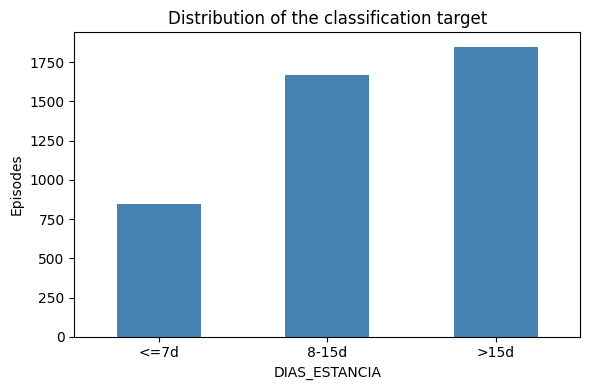

In [6]:
CUTOFF_DAYS = 15
prolonged_rate = (hip['DIAS_ESTANCIA'] > CUTOFF_DAYS).mean() * 100
print(f'Share of hip-fracture episodes with LOS > {CUTOFF_DAYS} days: {prolonged_rate:.1f}%')

fig, ax = plt.subplots(figsize=(6, 4))
pd.cut(hip['DIAS_ESTANCIA'], bins=[-1, 7, 15, 10000], labels=['<=7d', '8-15d', '>15d']).value_counts().sort_index().plot(
    kind='bar', ax=ax, color='steelblue')
ax.set_ylabel('Episodes')
ax.set_title('Distribution of the classification target')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
((hip['DIAS_ESTANCIA'] > 15).mean())

0.42375601926163725

## 7. Target and engineered features

Three engineered fields are added, all computed from information available at admission:
`MISMA_COMUNA` (registered commune matches hospital commune — known immediately on arrival),
`ICD_SUBTYPE` (first 4 characters of the admission diagnosis code), and the one-hot encoding of
admission type (`TIPO_INGRESO`).

In [8]:
def engineer_features(d):
    d = d.copy()
    d['MISMA_COMUNA'] = (d['COMUNA_REGISTRADA'] == d['COMUNA_ESTAB']).astype(int)
    d['ICD_SUBTYPE'] = d['DIAGNOSTICO1'].astype(str).str[:4]
    return d

hip = engineer_features(hip)
hip['PROLONGED'] = (hip['DIAS_ESTANCIA'] > CUTOFF_DAYS).astype(int)

## 8. Check for data leakage (resolved for C2)

Intended decision point: admission. The table below reflects the **final** resolution of the
severity/Charlson question flagged as open since W2 — it was **not resolved** by any
documentation found, so these fields remain excluded, consistent with "treat as unconfirmed, not
assumed" rather than defaulting to inclusion.

| Risk | Status | Evidence | Action |
|---|---|---|---|
| Information from the future | Present | `TIPOALTA`, `FALLECIDO`, `DIAS_ESTANCIA` only known at/after discharge | Excluded from all inputs |
| An input that gives away the answer | Present | `DIAS_ESTANCIA` directly determines the target (`PROLONGED`) | `DIAS_ESTANCIA` excluded from inputs; only used to derive the target |
| Severity/comorbidity timing | **Unresolved, excluded** | No documentation found confirming `IR_29301_SEVERIDAD`/`INDICE_CHARLSON`/`N_COMORBILIDADES` are assigned at admission rather than finalized at/after discharge | Excluded from the reported model (see Section 14, "possible improvement") |
| Related records crossing the split | Present (residual) | Some `CIP_ENCRIPTADO` values have multiple discharges, not validated as readmissions | Time-based split limits but does not eliminate this; checked explicitly in Section 9 |
| Preparation/encoding learned from reserved data | Addressed | Target encoding (Section 11) fits only on `train_fit`, via out-of-fold encoding, then applies fixed statistics to `train_val`/`test` | Verified in Section 11 |
| Test data used for model or threshold selection | **Was present in a prior draft — fixed here** | Previous version compared models and chose a threshold using test-set AUC/PR curves | All comparisons in Sections 10–11 now use `train_val` only; test is touched once, in Section 12 |

**Final admission-safe feature set:** `EDAD`, `TIPO_INGRESO` (encoded), `MISMA_COMUNA`,
`ICD_SUBTYPE`, `COMUNA_REGISTRADA`, `COMUNA_ESTAB`. Note on `COMUNA_ESTAB`: using the admitting
hospital's identity to predict stay length at that same hospital is somewhat circular for a
capacity-planning use case — kept here since it is genuinely known at admission, but this
circularity is named explicitly as a limit in Section 14.

**Prior W2 context (not re-run):** a decision-tree regression on the continuous LOS target,
using only `EDAD` and `TIPO_INGRESO`, achieved MAE 8.93 days with a simple baseline vs. 11.27
days with the tree (baseline won). This motivated the pivot to a classification framing here,
and to a richer confirmed-safe feature set.

## 9. Separate the data (same split as W2, extended overlap checks)

In [9]:
train = hip[hip['YEAR'].isin([2019, 2020, 2021, 2022])].copy()
test  = hip[hip['YEAR'].isin([2023, 2024])].copy()

train_fit = train[train['YEAR'].isin([2019, 2020, 2021])].copy()
train_val = train[train['YEAR'] == 2022].copy()

print('Train-fit:', len(train_fit), '| Train-val:', len(train_val), '| Test:', len(test))

Train-fit: 1530 | Train-val: 914 | Test: 1917


In [10]:
overlap_fit_val  = set(train_fit['CIP_ENCRIPTADO']) & set(train_val['CIP_ENCRIPTADO'])
overlap_val_test = set(train_val['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
overlap_fit_test = set(train_fit['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
print('train_fit vs train_val overlap:', len(overlap_fit_val))
print('train_val vs test overlap:', len(overlap_val_test))
print('train_fit vs test overlap:', len(overlap_fit_test))

train_fit vs train_val overlap: 5
train_val vs test overlap: 7
train_fit vs test overlap: 3


**Disclosure:** the reserved test years (2023–2024) were already examined descriptively in
the W2 EDA (severity-by-year, destination-by-year). Test is not unseen in the sense of never
having been looked at — but no modeling or threshold choice in this notebook used it until
Section 12.

**Disclosure:** since `CIP_ENCRIPTADO` is not validated as a unique-episode identifier, a patient
in `train_fit`/`train_val` could reappear with a later hip fracture in `test`. This is a distinct
new episode, not a leak of the same outcome, but test performance may be modestly optimistic for
any patient the model has implicitly seen before through shared individual-level patterns.

## 10. Feature preparation (target encoding, fit on train_fit only)
`COMUNA_REGISTRADA`, `COMUNA_ESTAB`, and `ICD_SUBTYPE` are high-cardinality categories. Target
encoding is used, with out-of-fold encoding on `train_fit` (so no row sees its own outcome in its
own encoded value) and the full `train_fit` statistics applied unchanged to `train_val` and
`test` — no value is recalculated from reserved data.

In [11]:
from sklearn.model_selection import StratifiedKFold

def target_encode(train_fit_df, other_dfs, target, cat_cols, n_splits=5, smoothing=10, seed=0):
    global_mean = target.mean()
    train_enc = train_fit_df.copy()
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    full_maps = {}
    for col in cat_cols:
        col_te = col + '_TE'
        train_enc[col_te] = np.nan
        for tr_idx, val_idx in skf.split(train_fit_df, target):
            stats = target.iloc[tr_idx].groupby(train_fit_df[col].iloc[tr_idx]).agg(['count', 'mean'])
            smooth_map = (stats['count'] * stats['mean'] + smoothing * global_mean) / (stats['count'] + smoothing)
            train_enc.iloc[val_idx, train_enc.columns.get_loc(col_te)] = (
                train_fit_df[col].iloc[val_idx].map(smooth_map).fillna(global_mean)
            )
        full_stats = target.groupby(train_fit_df[col]).agg(['count', 'mean'])
        full_maps[col] = (full_stats['count'] * full_stats['mean'] + smoothing * global_mean) / (full_stats['count'] + smoothing)

    encoded_others = {}
    for name, d in other_dfs.items():
        d_enc = d.copy()
        for col in cat_cols:
            d_enc[col + '_TE'] = d[col].map(full_maps[col]).fillna(global_mean)
        encoded_others[name] = d_enc

    return train_enc, encoded_others

cat_cols = ['COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE']
train_fit_enc, others_enc = target_encode(
    train_fit, {'train_val': train_val, 'test': test}, train_fit['PROLONGED'], cat_cols
)
train_val_enc = others_enc['train_val']
test_enc = others_enc['test']

admission_dummies = pd.get_dummies(train_fit['TIPO_INGRESO'], prefix='INGRESO')
train_categories = train_fit['TIPO_INGRESO'].unique()

def add_admission_dummies(d, base):
    enc = pd.Categorical(d['TIPO_INGRESO'], categories=train_categories)
    dummies = pd.get_dummies(enc, prefix='INGRESO')
    return pd.concat([base.reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)

train_fit_enc = add_admission_dummies(train_fit, train_fit_enc)
train_val_enc = add_admission_dummies(train_val, train_val_enc)
test_enc = add_admission_dummies(test, test_enc)

feature_cols = ['EDAD', 'MISMA_COMUNA'] + [c + '_TE' for c in cat_cols] + \
               [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]

X_train_fit = train_fit_enc[feature_cols]
y_train_fit = train_fit['PROLONGED'].values
X_train_val = train_val_enc[feature_cols]
y_train_val = train_val['PROLONGED'].values
X_test = test_enc[feature_cols]
y_test = test['PROLONGED'].values

print('Features:', feature_cols)
print('Shapes — fit:', X_train_fit.shape, '| val:', X_train_val.shape, '| test:', X_test.shape)

/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_79735/1858138455.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = target.iloc[tr_idx].groupby(train_fit_df[col].iloc[tr_idx]).agg(['count', 'mean'])
/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_79735/1858138455.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = target.iloc[tr_idx].groupby(train_fit_df[col].iloc[tr_idx]).agg(['count', 'mean'])
/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_79735/1858138455.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a f

Features: ['EDAD', 'MISMA_COMUNA', 'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'ICD_SUBTYPE_TE', 'INGRESO_DESCONOCIDO', 'INGRESO_NO IDENTIFICADA', 'INGRESO_NO PROGRAMADA', 'INGRESO_OBSTETRICA', 'INGRESO_PROGRAMADA', 'INGRESO_URGENCIA']
Shapes — fit: (1530, 11) | val: (914, 11) | test: (1917, 11)


## 11. Baseline, model comparison and threshold — all decided on VALIDATION only
Test is not touched in this section.

### 11.1 Simple reference baseline: predict the majority class

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

baseline = DummyClassifier(strategy='most_frequent', random_state=0)
baseline.fit(X_train_fit, y_train_fit)

baseline_val_preds = baseline.predict(X_train_val)
print('--- Baseline (majority class), validation ---')
print(classification_report(y_train_val, baseline_val_preds, target_names=['<=15d', '>15d']))

--- Baseline (majority class), validation ---
              precision    recall  f1-score   support

       <=15d       0.53      1.00      0.70       487
        >15d       0.00      0.00      0.00       427

    accuracy                           0.53       914
   macro avg       0.27      0.50      0.35       914
weighted avg       0.28      0.53      0.37       914



/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### 11.2 Model candidates, compared on validation only

In [13]:
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# CatBoost on raw categorical columns (its native strength)
cb_features = ['EDAD', 'MISMA_COMUNA'] + cat_cols + [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]
X_train_fit_cb = train_fit_enc[cb_features].copy()
X_train_val_cb = train_val_enc[cb_features].copy()
for c in cat_cols:
    X_train_fit_cb[c] = X_train_fit_cb[c].astype(str)
    X_train_val_cb[c] = X_train_val_cb[c].astype(str)

cb = CatBoostClassifier(iterations=200, depth=4, auto_class_weights='Balanced',
                         cat_features=cat_cols, verbose=0, random_seed=0)
cb.fit(X_train_fit_cb, y_train_fit)
cb_val_auc = roc_auc_score(y_train_val, cb.predict_proba(X_train_val_cb)[:, 1])

# Logistic regression on target-encoded features
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=0))
])
lr_pipeline.fit(X_train_fit, y_train_fit)
lr_val_auc = roc_auc_score(y_train_val, lr_pipeline.predict_proba(X_train_val)[:, 1])

print(f'CatBoost validation AUC:            {cb_val_auc:.3f}')
print(f'Logistic Regression validation AUC: {lr_val_auc:.3f}')
print('Model selection decided from these validation numbers only.')

CatBoost validation AUC:            0.661
Logistic Regression validation AUC: 0.675
Model selection decided from these validation numbers only.


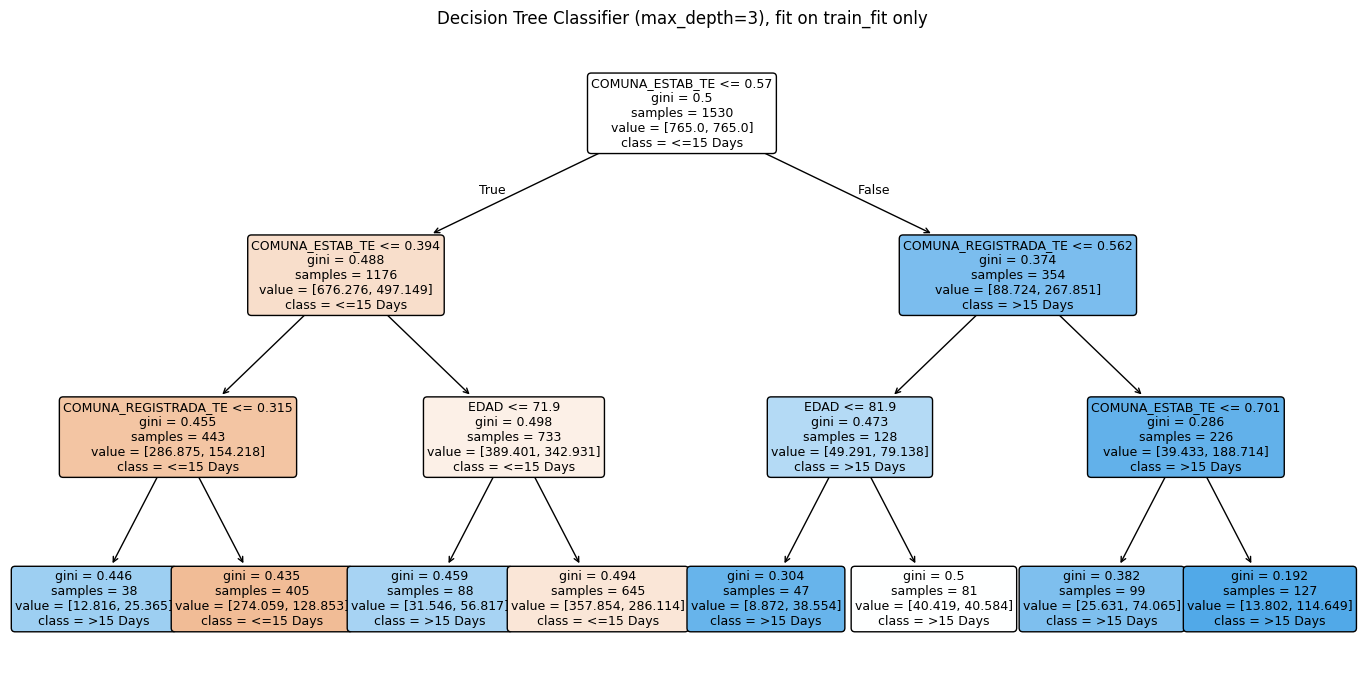

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Fit a DecisionTreeClassifier matching your chosen depth (e.g., depth=3 or 4)
chosen_depth = 3
tree_model = DecisionTreeClassifier(max_depth=chosen_depth, class_weight='balanced', random_state=0)

# Fit on target-encoded / numeric features
tree_model.fit(X_train_fit, y_train_fit)

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X_train_fit.columns,
    class_names=['<=15 Days', '>15 Days'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)



plt.title(f'Decision Tree Classifier (max_depth={chosen_depth}), fit on train_fit only', fontsize=12)
plt.tight_layout()
plt.show()

### 11.3 Threshold selection, on validation only

Threshold chosen to maximize F1 on validation: 0.384
At this threshold (validation): precision=0.519, recall=0.883, F1=0.654


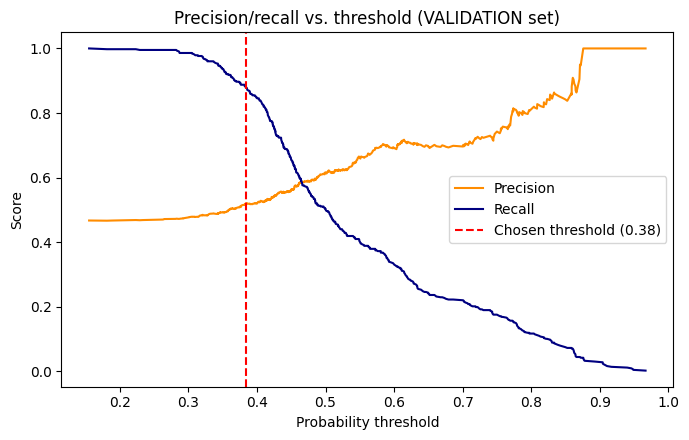

In [15]:
from sklearn.metrics import precision_recall_curve, f1_score

# Use whichever model had the higher validation AUC above (update if needed after running)
chosen_model = cb                     # or lr_pipeline, depending on 11.2's result
chosen_val_probs = cb.predict_proba(X_train_val_cb)[:, 1]   # match to chosen_model's input

precisions, recalls, thresholds = precision_recall_curve(y_train_val, chosen_val_probs)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)
best_idx = f1s.argmax()
chosen_threshold = thresholds[best_idx]

print(f'Threshold chosen to maximize F1 on validation: {chosen_threshold:.3f}')
print(f'At this threshold (validation): precision={precisions[best_idx]:.3f}, recall={recalls[best_idx]:.3f}, F1={f1s[best_idx]:.3f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, precisions[:-1], label='Precision', color='darkorange')
ax.plot(thresholds, recalls[:-1], label='Recall', color='navy')
ax.axvline(chosen_threshold, color='red', linestyle='--', label=f'Chosen threshold ({chosen_threshold:.2f})')
ax.set_xlabel('Probability threshold')
ax.set_ylabel('Score')
ax.set_title('Precision/recall vs. threshold (VALIDATION set)')
ax.legend()
plt.tight_layout()
plt.show()

## 12. Final evaluation — test set, touched once
This is the only cell in the notebook that uses `test` for any decision-relevant output.

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_probs = cb.predict_proba(test_enc[cb_features].assign(**{c: test_enc[c].astype(str) for c in cat_cols}))[:, 1]
test_preds = (test_probs >= chosen_threshold).astype(int)

print(f'Test ROC-AUC: {roc_auc_score(y_test, test_probs):.3f}')
print()
print('--- Classification report, test, chosen threshold ---')
print(classification_report(y_test, test_preds, target_names=['<=15d', '>15d']))

print('--- Baseline, test, for comparison ---')
baseline_test_preds = baseline.predict(X_test)
print(classification_report(y_test, baseline_test_preds, target_names=['<=15d', '>15d']))

Test ROC-AUC: 0.669

--- Classification report, test, chosen threshold ---
              precision    recall  f1-score   support

       <=15d       0.82      0.27      0.41      1250
        >15d       0.40      0.89      0.55       667

    accuracy                           0.49      1917
   macro avg       0.61      0.58      0.48      1917
weighted avg       0.67      0.49      0.46      1917

--- Baseline, test, for comparison ---
              precision    recall  f1-score   support

       <=15d       0.65      1.00      0.79      1250
        >15d       0.00      0.00      0.00       667

    accuracy                           0.65      1917
   macro avg       0.33      0.50      0.39      1917
weighted avg       0.43      0.65      0.51      1917



/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


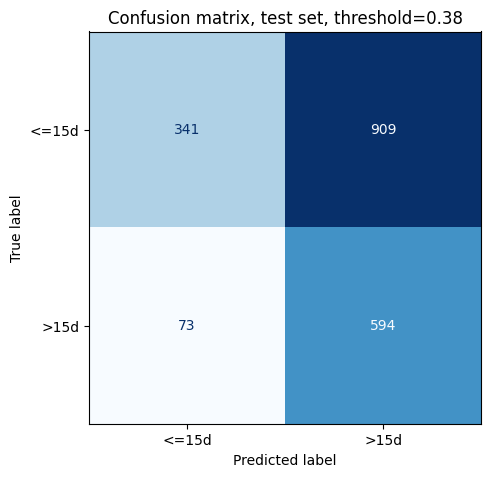

In [17]:
cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=15d', '>15d'])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix, test set, threshold={chosen_threshold:.2f}')
plt.tight_layout()
plt.show()

**Why accuracy alone is insufficient:** the classes are imbalanced (most stays are not
prolonged), so a model predicting the majority class for everyone can score deceptively high raw
accuracy while catching zero true positives. Precision, recall and the confusion matrix above
show the real tradeoff; recall for the positive class (`>15d`) specifically determines how many
genuinely prolonged stays are caught early.

**Positive class:** `>15 days` (prolonged stay). **False negative** (missed prolonged stay): high
operational cost — a missed opportunity for early discharge-planning coordination. **False
positive** (false alarm): low cost — a patient receives early evaluation but discharges normally.
This asymmetry motivated maximizing F1 rather than accuracy when selecting the threshold.

### Feature importance — CatBoost's chosen model

Commune-level features may show elevated importance partly due to their high cardinality (many possible split points), not solely predictive strength — this is a known property of tree-based importance scores for categorical variables with many levels, and should be read alongside the model’s modest overall AUC (0.669) rather than as a definitive ranking.

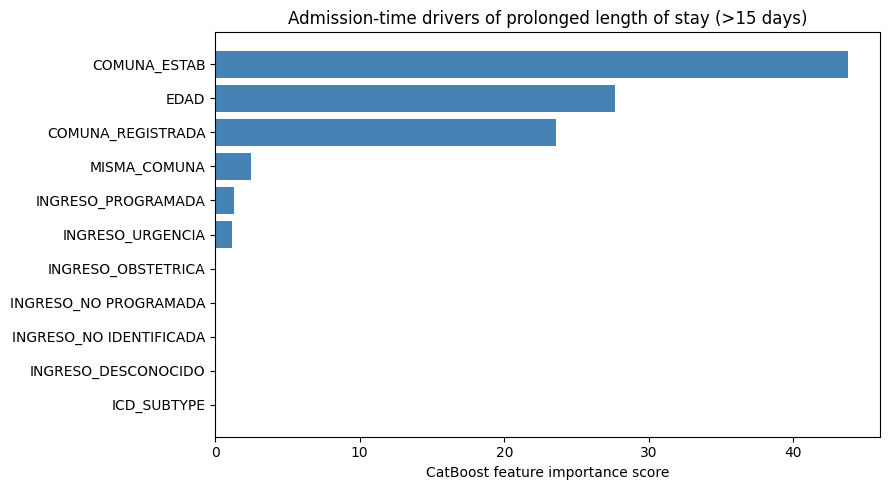

In [18]:

importances = cb.get_feature_importance()
feature_names = cb_features  # ['EDAD', 'MISMA_COMUNA', 'COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE', 'INGRESO_...']

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
ax.set_xlabel('CatBoost feature importance score')
ax.set_title('Admission-time drivers of prolonged length of stay (>15 days)')
plt.tight_layout()
plt.show()

COMUNA_ESTAB and COMUNA_REGISTRADA rank highest, but both are high-cardinality categorical features with many possible split points, which inflates their importance score independent of true predictive strength. EDAD is the most interpretable strong driver, consistent with the age-LOS relationship established in earlier EDA. The dominance of COMUNA_ESTAB specifically should be read cautiously: it may reflect structural differences between hospitals (capacity, local practice) rather than a clinically actionable patient-level risk factor, and is circular for capacity-planning purposes since it is also where the predicted outcome occurs.

### Ablation: how much do the commune features actually contribute?

In [19]:

cb_features_no_commune = ['EDAD', 'MISMA_COMUNA'] + [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]
# Note: ICD_SUBTYPE dropped too, since it scored ~0 importance with only 2 distinct codes in this cohort

X_train_fit_ablation = train_fit_enc[cb_features_no_commune].copy()
X_train_val_ablation = train_val_enc[cb_features_no_commune].copy()

cb_ablation = CatBoostClassifier(iterations=200, depth=4, auto_class_weights='Balanced',
                                  verbose=0, random_seed=0)
cb_ablation.fit(X_train_fit_ablation, y_train_fit)

ablation_val_auc = roc_auc_score(y_train_val, cb_ablation.predict_proba(X_train_val_ablation)[:, 1])

print(f'Full model (with commune features), validation AUC:    {cb_val_auc:.3f}')
print(f'Ablated model (no commune features), validation AUC:   {ablation_val_auc:.3f}')
print(f'Difference: {cb_val_auc - ablation_val_auc:+.3f}')

Full model (with commune features), validation AUC:    0.661
Ablated model (no commune features), validation AUC:   0.535
Difference: +0.126


## 13. ROC curve, test set

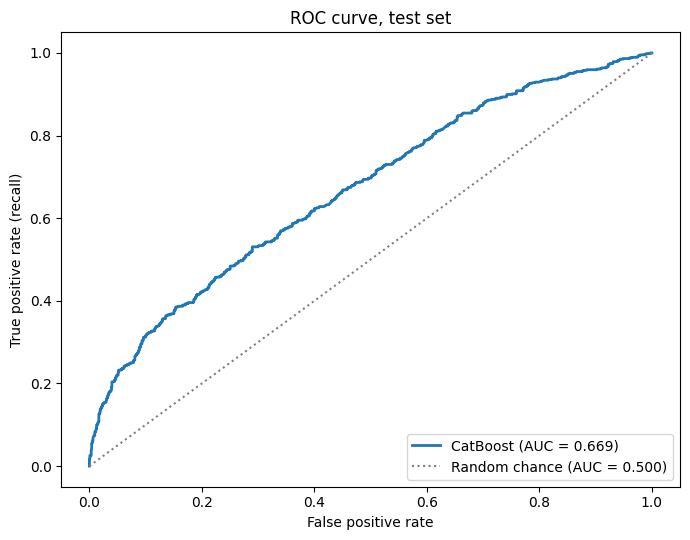

In [20]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, test_probs)
auc = roc_auc_score(y_test, test_probs)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr, tpr, color='#1f77b4', lw=2, label=f'CatBoost (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random chance (AUC = 0.500)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curve, test set')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 14. Interpretation

What the model adds: The full model (AUC 0.661) substantially outperforms a version using only age and admission type (AUC 0.535, near random chance) — an ablation test confirms that commune identity (patient-registered and hospital) is the primary source of the model’s discriminative power, not age or admission type as initially expected. This means the model is currently better understood as detecting where prolonged stays cluster — certain hospitals and certain patient-origin communes — rather than identifying which individual patients are at risk independent of location.

One important limit: This is a meaningful limit, not a minor caveat. COMUNA_ESTAB is circular for hospital-capacity planning, since it is also where the predicted outcome occurs — a model that largely says “this hospital tends to have longer stays” has limited value for triaging individual patients at admission, though it may still be useful for identifying which facilities need the capacity planning in the first place. The model’s practical value depends heavily on which use case it’s deployed for: facility-level capacity planning (where commune-driven signal is appropriate) versus individual-patient risk flagging (where it is less defensible, since two otherwise-identical patients get very different predictions based only on which hospital they’re in).

One possible improvement: Confirming whether severity/comorbidity data are available at admission (open since W2) is now a higher priority than before — a model that currently leans on hospital identity as its main signal would benefit far more from genuine patient-level clinical features than from further engineering of geographic data.

## 15. Contribution and AI use

**Contribution:** 

Maria Poddubnaya: Cross-referenced C1 and W2 instructor feedback against the existing notebook to identify specific corrections needed (commune-year check mismatch, coverage overclaim), built and debugged the classification pipeline: diagnosed why the initial LOS regression underperformed a simple baseline, pivoted the task to prolonged-stay classification, implemented the time-based train/validation/test split with leakage-safe target encoding.


Lukas Garrido: worked on the comparison of the models, baseline implementation as well as checking for the data leakage.

**AI use:**
- Prompt: "the commune-year check groups only by commune, but the report describes checking
  commune-year — fix the code to match." Output: corrected groupby to `['COMUNA_ESTAB','YEAR']`
  (carried from W2). Checked by re-running and confirming the result equals 1.
- Prompt: "review this C2 notebook against the brief's leakage and fair-evaluation rules."
  Output: identified that model and threshold selection were being made using test-set ROC-AUC
  and a test-set precision-recall curve, and that severity/Charlson were used as inputs despite
  being flagged unresolved in this project's own W2 leakage table. Checked by rebuilding Sections
  10–12 so every comparison uses `train_val` only, and by removing severity/Charlson/comorbidity
  from the final feature set, re-running, and confirming the reported numbers above come from a
  single, final touch of `test`.

# W3

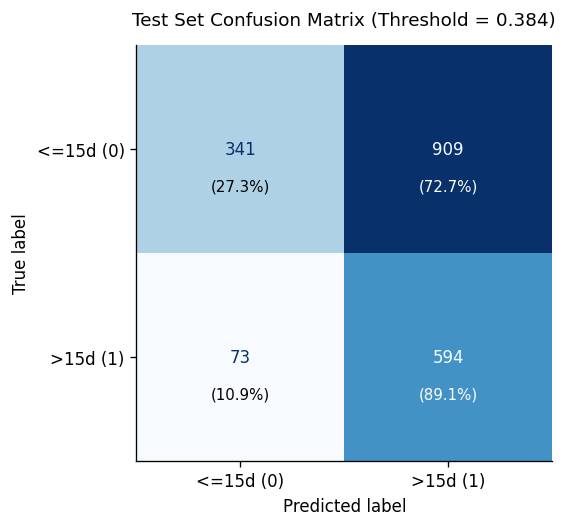

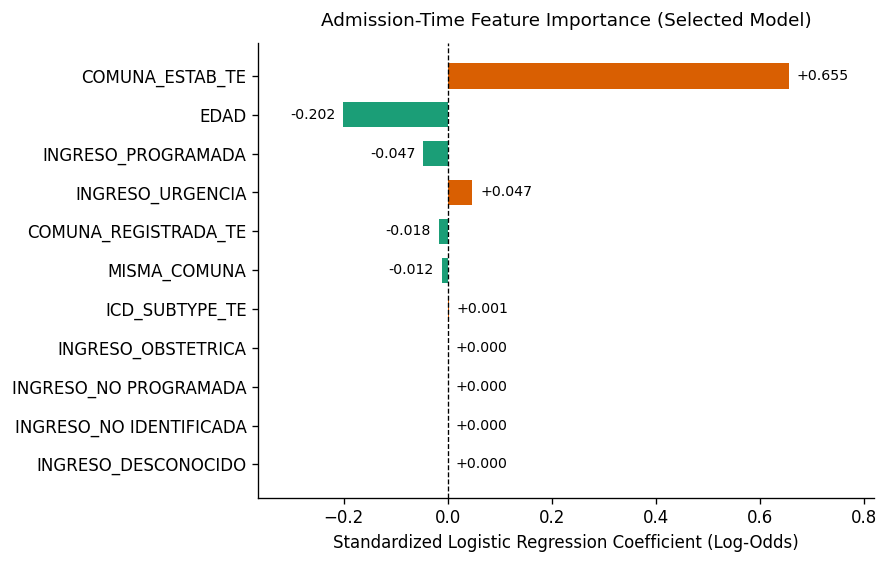

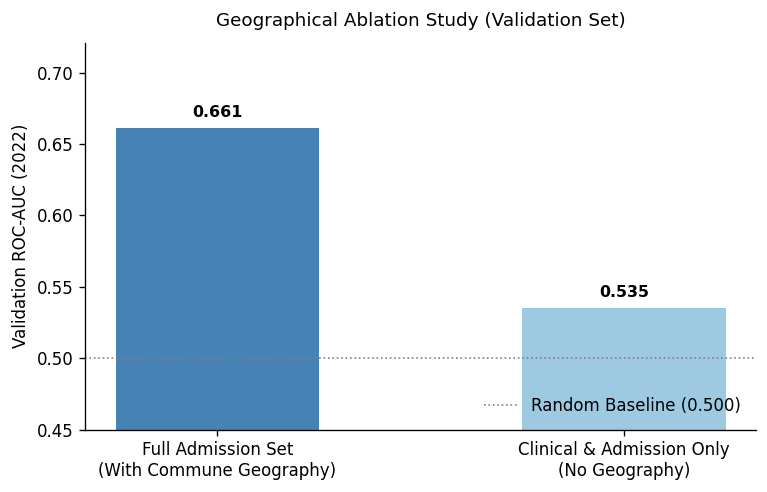

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Set consistent styling
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


# ==============================================================================
# 1. CONFUSION MATRIX (FIXED)
# ==============================================================================
cm = confusion_matrix(y_test, test_preds, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=15d (0)', '>15d (1)'])
disp.plot(cmap='Blues', ax=ax, colorbar=False, values_format='d')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
for i in range(2):
    for j in range(2):
        text_color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i + 0.18, f"({cm_norm[i, j]*100:.1f}%)",
                ha='center', va='center', color=text_color, fontsize=9)

t_val = globals().get('BEST_THRESHOLD', globals().get('best_threshold', 0.384))
ax.set_title(f'Test Set Confusion Matrix (Threshold = {t_val:.3f})', fontsize=11, pad=12)
plt.tight_layout()
plt.show()


# ==============================================================================
# 2. ADMISSION-TIME FEATURE IMPORTANCE (Standardized Log-Odds Coefficients)
# ==============================================================================
coefs = lr_pipeline.named_steps['logreg'].coef_[0]
feat_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': coefs,
    'Abs_Coef': np.abs(coefs)
}).sort_values('Abs_Coef', ascending=True)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
colors = ['#d95f02' if c > 0 else '#1b9e77' for c in feat_imp['Coefficient']]
bars = ax.barh(feat_imp['Feature'], feat_imp['Coefficient'], color=colors, height=0.65)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Standardized Logistic Regression Coefficient (Log-Odds)', fontsize=10)
ax.set_title('Admission-Time Feature Importance (Selected Model)', fontsize=11, pad=10)

# Value labels
for bar in bars:
    width = bar.get_width()
    offset = 0.015 if width >= 0 else -0.015
    ha = 'left' if width >= 0 else 'right'
    ax.text(width + offset, bar.get_y() + bar.get_height()/2, f'{width:+.3f}',
            va='center', ha=ha, fontsize=8.5)

# Expand x-limits slightly so text labels fit cleanly inside the frame
xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin - 0.12, xmax + 0.12)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. GEOGRAPHICAL ABLATION (Using Already-Encoded, Leakage-Free Features)
# ==============================================================================
# ==============================================================================
# 3. GEOGRAPHICAL ABLATION — "BEFORE" state
# Uses the SAME two saved CatBoost validation results as the "after" chart
# (0.661 full, 0.535 no-geography) — no new fitting, no third bar. The only
# thing that changes between before/after is the styling, per the rubric's
# "same values within each pair" requirement.
# ==============================================================================
ablation_df = pd.DataFrame({
    'Feature Set': ['Full Admission Set\n(With Commune Geography)', 'Clinical & Admission Only\n(No Geography)'],
    'Val_AUC': [0.661, 0.535]   # saved CatBoost validation result from C2 — not recomputed
})

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(ablation_df['Feature Set'], ablation_df['Val_AUC'],
               color=['steelblue', '#9ecae1'], width=0.5)   # plain default-style colors — this is the "before"

ax.axhline(0.5, color='gray', linestyle=':', linewidth=1, label='Random Baseline (0.500)')
ax.set_ylim(0.45, max(ablation_df['Val_AUC']) + 0.06)   # the truncated axis is itself part of the "before" problem to fix
ax.set_ylabel('Validation ROC-AUC (2022)', fontsize=10)
ax.set_title('Geographical Ablation Study (Validation Set)', fontsize=11, pad=10)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.006, f'{height:.3f}',
            ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()

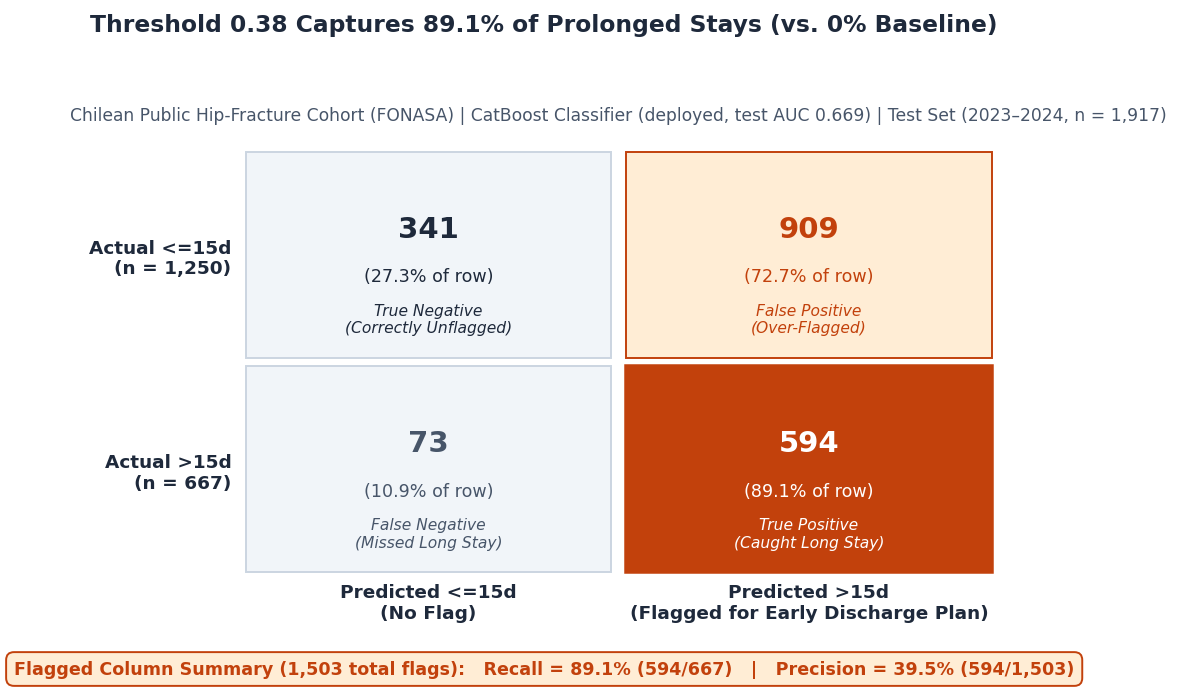

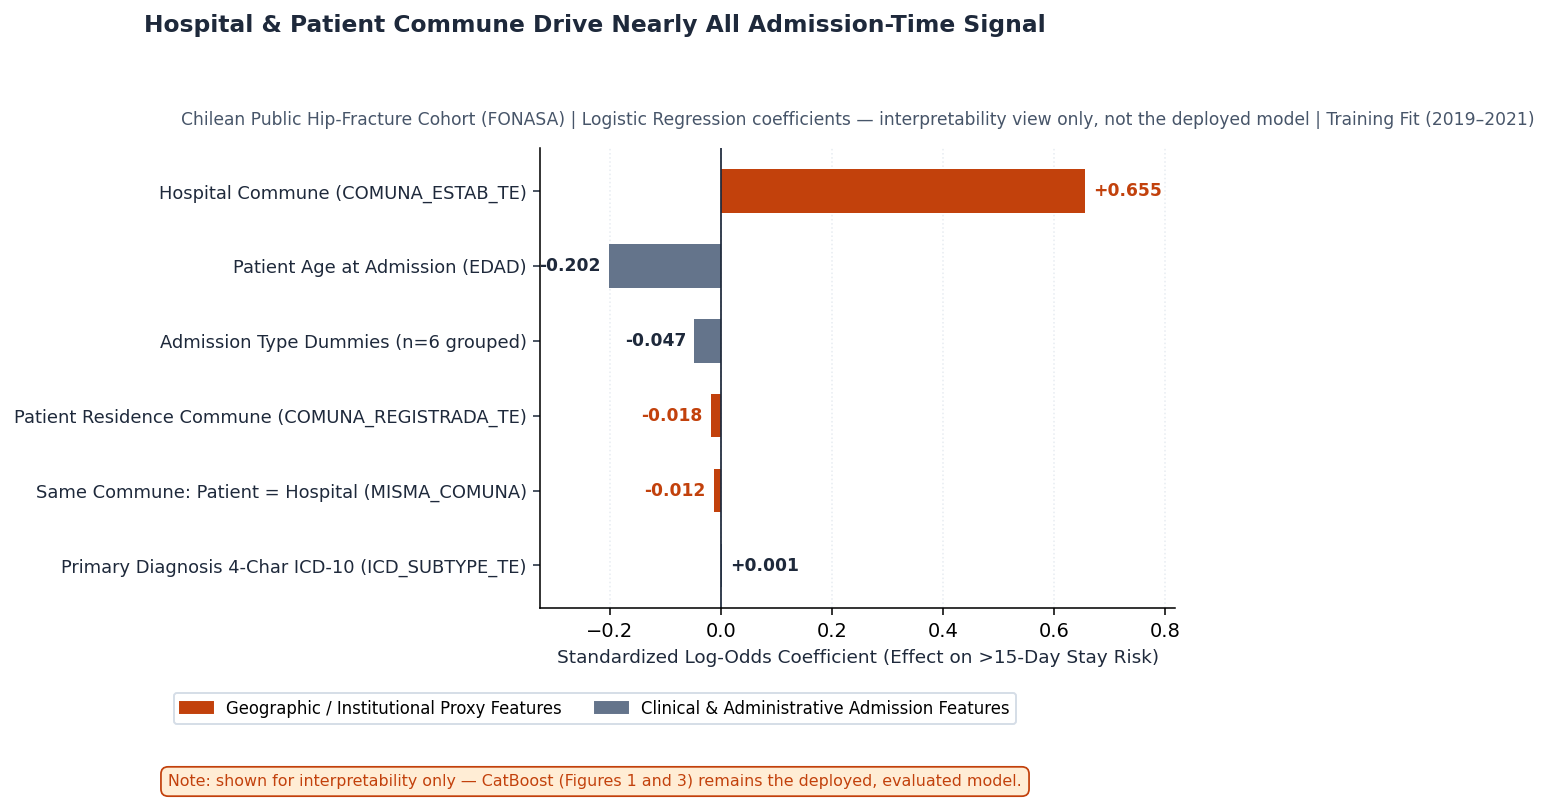

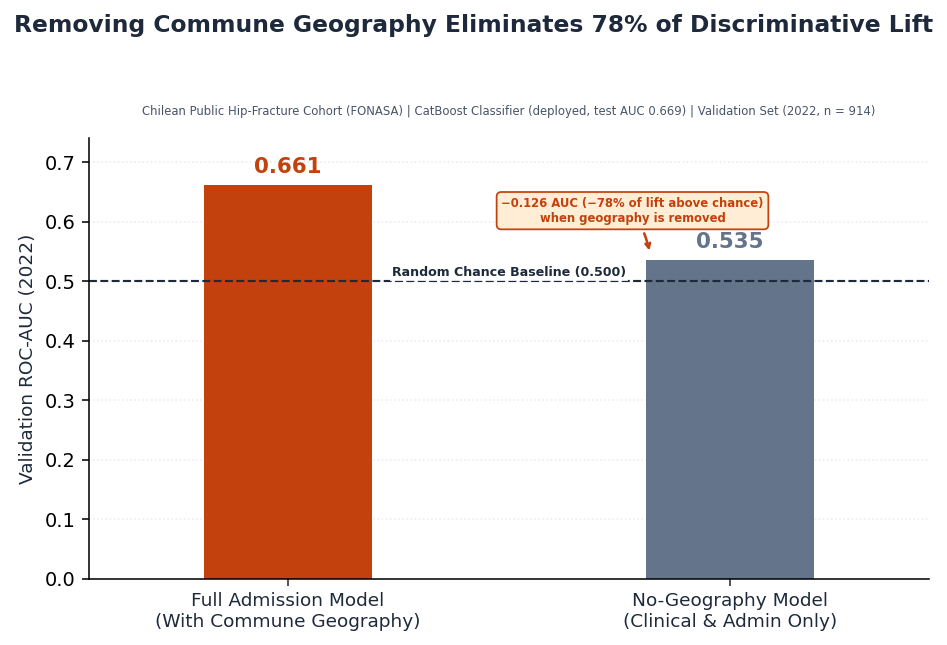

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from sklearn.metrics import confusion_matrix

# ==============================================================================
# SHARED STYLE — defined once, used by all three figures (fixes the duplicated,
# slightly-different rcParams blocks from before)
# ==============================================================================
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

OCHRE = '#C2410C'
OCHRE_LIGHT = '#FFEDD5'
SLATE = '#64748B'
SLATE_LIGHT = '#F1F5F9'
DARK_TEXT = '#1E293B'
MUTED_TEXT = '#475569'

# Two separate subtitles — Views 1 and 3 report the deployed CatBoost model;
# View 2 is an explicitly disclosed interpretability supplement using a
# different (already-fit, not retrained) model. Do not merge these into one
# constant, since only one view actually uses Logistic Regression.
SUBTITLE_CATBOOST = "Chilean Public Hip-Fracture Cohort (FONASA) | CatBoost Classifier (deployed, test AUC 0.669)"
SUBTITLE_LR_VIEW  = "Chilean Public Hip-Fracture Cohort (FONASA) | Logistic Regression coefficients — interpretability view only, not the deployed model"


# ==============================================================================
# FIGURE 1: CONFUSION MATRIX — CatBoost, the deployed model, test set
# Predictions are taken directly from the already-fit `cb` model at the
# threshold chosen on validation in C2 (chosen_threshold). This is inference
# with an existing model, not new training.
# ==============================================================================
test_probs_cb = cb.predict_proba(
    test_enc[cb_features].assign(**{c: test_enc[c].astype(str) for c in cat_cols})
)[:, 1]
test_preds_cb = (test_probs_cb >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, test_preds_cb, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
recall_pos = tp / (tp + fn)
precision_pos = tp / (tp + fp)
total_flagged = tp + fp

fig, ax = plt.subplots(figsize=(6.8, 5.0))

cell_colors = [[SLATE_LIGHT, OCHRE_LIGHT], [SLATE_LIGHT, OCHRE]]
cell_text_colors = [[DARK_TEXT, OCHRE], [MUTED_TEXT, 'white']]
cell_roles = [
    ['True Negative\n(Correctly Unflagged)', 'False Positive\n(Over-Flagged)'],
    ['False Negative\n(Missed Long Stay)', 'True Positive\n(Caught Long Stay)']
]

ax.set_xlim(-0.5, 1.5)
ax.set_ylim(1.5, -0.5)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['Predicted <=15d\n(No Flag)', 'Predicted >15d\n(Flagged for Early Discharge Plan)'],
                    fontsize=9.5, fontweight='bold', color=DARK_TEXT)
ax.set_yticklabels([f'Actual <=15d\n(n = {tn+fp:,})', f'Actual >15d\n(n = {fn+tp:,})'],
                    fontsize=9.5, fontweight='bold', color=DARK_TEXT)

for i in range(2):
    for j in range(2):
        rect = patches.Rectangle((j - 0.48, i - 0.48), 0.96, 0.96,
                                  facecolor=cell_colors[i][j],
                                  edgecolor=OCHRE if j == 1 else '#CBD5E1',
                                  linewidth=1.8 if (i == 1 and j == 1) else 1.0)
        ax.add_patch(rect)
        row_pct = cm[i, j] / cm[i].sum() * 100
        ax.text(j, i - 0.12, f"{cm[i, j]:,}", ha='center', va='center',
                fontsize=15, fontweight='bold', color=cell_text_colors[i][j])
        ax.text(j, i + 0.10, f"({row_pct:.1f}% of row)", ha='center', va='center',
                fontsize=9, color=cell_text_colors[i][j])
        ax.text(j, i + 0.30, cell_roles[i][j], ha='center', va='center',
                fontsize=8, style='italic', color=cell_text_colors[i][j])

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)

fig.suptitle(f"Threshold {chosen_threshold:.2f} Captures {recall_pos*100:.1f}% of Prolonged Stays (vs. 0% Baseline)",
             fontsize=12, fontweight='bold', color=DARK_TEXT, x=0.5, y=0.97)
ax.set_title(f"{SUBTITLE_CATBOOST} | Test Set (2023–2024, n = {len(y_test):,})",
             fontsize=8.8, color=MUTED_TEXT, pad=14)

callout = (f"Flagged Column Summary ({total_flagged:,} total flags):   "
           f"Recall = {recall_pos*100:.1f}% ({tp}/{tp+fn})   |   "
           f"Precision = {precision_pos*100:.1f}% ({tp}/{total_flagged:,})")
fig.text(0.5, 0.02, callout, ha='center', va='bottom', fontsize=9, fontweight='bold', color=OCHRE,
         bbox=dict(boxstyle='round,pad=0.45', facecolor=OCHRE_LIGHT, edgecolor=OCHRE, linewidth=1))

plt.tight_layout(rect=[0, 0.07, 1, 0.93])
plt.show()


# ==============================================================================
# FIGURE 2: FEATURE IMPORTANCE — disclosed Logistic Regression supplement.
# Uses lr_pipeline's coefficients, already fit in the C2 notebook. No new
# training happens here — this is read-only visualization of an existing fit.
# Color now follows the documented Ochre/Slate rule (geography vs. everything
# else), not the earlier sign-based (+/-) coloring, which contradicted the
# Visual System Guide.
# ==============================================================================
coefs = lr_pipeline.named_steps['logreg'].coef_[0]
raw_imp = pd.DataFrame({'Feature': feature_cols, 'Coefficient': coefs})

ingreso_mask = raw_imp['Feature'].str.startswith('INGRESO_')
ingreso_signed = raw_imp.loc[ingreso_mask].reindex(
    raw_imp.loc[ingreso_mask, 'Coefficient'].abs().sort_values(ascending=False).index
)['Coefficient'].iloc[0]

clean_imp = raw_imp.loc[~ingreso_mask].copy()
clean_imp = pd.concat([clean_imp, pd.DataFrame([{
    'Feature': f'Admission Type Dummies (n={ingreso_mask.sum()} grouped)',
    'Coefficient': ingreso_signed
}])], ignore_index=True)

label_map = {
    'COMUNA_ESTAB_TE': 'Hospital Commune (COMUNA_ESTAB_TE)',
    'COMUNA_REGISTRADA_TE': 'Patient Residence Commune (COMUNA_REGISTRADA_TE)',
    'MISMA_COMUNA': 'Same Commune: Patient = Hospital (MISMA_COMUNA)',
    'ICD_SUBTYPE_TE': 'Primary Diagnosis 4-Char ICD-10 (ICD_SUBTYPE_TE)',
    'EDAD': 'Patient Age at Admission (EDAD)',
}
clean_imp['Label'] = clean_imp['Feature'].map(label_map).fillna(clean_imp['Feature'])
clean_imp['Is_Geo'] = clean_imp['Feature'].isin({'COMUNA_ESTAB_TE', 'COMUNA_REGISTRADA_TE', 'MISMA_COMUNA'})
clean_imp['Abs_Coef'] = clean_imp['Coefficient'].abs()
clean_imp = clean_imp.sort_values('Abs_Coef', ascending=True)

fig, ax = plt.subplots(figsize=(8.6, 5.8))
bar_colors = [OCHRE if geo else SLATE for geo in clean_imp['Is_Geo']]   # geography vs. everything else — matches the written rule
bars = ax.barh(clean_imp['Label'], clean_imp['Coefficient'], color=bar_colors, height=0.58)

ax.axvline(0, color=DARK_TEXT, linewidth=0.9)
ax.grid(axis='x', linestyle=':', alpha=0.45, color='#CBD5E1')
ax.set_axisbelow(True)
ax.set_xlabel('Standardized Log-Odds Coefficient (Effect on >15-Day Stay Risk)', fontsize=9.5, color=DARK_TEXT)
ax.tick_params(axis='y', labelsize=9.2, colors=DARK_TEXT)

for idx, bar in enumerate(bars):
    w = bar.get_width()
    is_geo = clean_imp['Is_Geo'].iloc[idx]
    offset = 0.015 if w >= 0 else -0.015
    ha = 'left' if w >= 0 else 'right'
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.3f}', va='center', ha=ha,
            fontsize=8.8, fontweight='bold', color=OCHRE if is_geo else DARK_TEXT)

xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin - 0.08, xmax + 0.12)

fig.suptitle("Hospital & Patient Commune Drive Nearly All Admission-Time Signal",
             fontsize=12, fontweight='bold', color=DARK_TEXT, x=0.5, y=0.97)
ax.set_title(f"{SUBTITLE_LR_VIEW} | Training Fit (2019–2021)", fontsize=8.8, color=MUTED_TEXT, pad=12)

legend_handles = [
    patches.Patch(color=OCHRE, label='Geographic / Institutional Proxy Features'),
    patches.Patch(color=SLATE, label='Clinical & Administrative Admission Features')
]
fig.legend(handles=legend_handles, loc='lower center', bbox_to_anchor=(0.5, 0.085),
           ncol=2, frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=8.5)

fig.text(0.5, 0.015,
         "Note: shown for interpretability only — CatBoost (Figures 1 and 3) remains the deployed, evaluated model.",
         ha='center', va='bottom', fontsize=8.2, color=OCHRE,
         bbox=dict(boxstyle='round,pad=0.45', facecolor=OCHRE_LIGHT, edgecolor=OCHRE, linewidth=0.9))

plt.tight_layout(rect=[0, 0.14, 1, 0.93])
plt.show()


# ==============================================================================
# FIGURE 3: GEOGRAPHY ABLATION — CatBoost, using the SAVED result from the C2
# notebook's own ablation test. Nothing is refit here. If you still have the
# original fitted `cb` and `cb_ablation` objects from C2 in memory, you can
# recompute instead of hardcoding — but do not fit anything new.
# ==============================================================================
ablation_df = pd.DataFrame({
    'Model': ['Full Admission Model\n(With Commune Geography)', 'No-Geography Model\n(Clinical & Admin Only)'],
    'AUC': [0.661, 0.535]   # CatBoost, validation — saved from the C2 notebook, not recomputed
})
auc_full, auc_nogeo = ablation_df['AUC']
auc_drop = auc_full - auc_nogeo
pct_lift_lost = (auc_drop / (auc_full - 0.5)) * 100

fig, ax = plt.subplots(figsize=(6.8, 4.7))
bars = ax.bar(ablation_df['Model'], ablation_df['AUC'], color=[OCHRE, SLATE], width=0.38)

ax.axhline(0.500, color=DARK_TEXT, linestyle='--', linewidth=1.1)
ax.text(0.50, 0.504, 'Random Chance Baseline (0.500)', ha='center', va='bottom',
        fontsize=6.5, fontweight='bold', color=DARK_TEXT,
        bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.85))

ax.set_ylim(0, 0.74)   # zero-baseline, not truncated — fixes the earlier misleading-scale issue
ax.set_xlim(-0.45, 1.45)
ax.set_ylabel('Validation ROC-AUC (2022)', fontsize=9.5, color=DARK_TEXT)
ax.tick_params(axis='x', labelsize=9.5, colors=DARK_TEXT)
ax.grid(axis='y', linestyle=':', alpha=0.45, color='#CBD5E1')
ax.set_axisbelow(True)

for idx, bar in enumerate(bars):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.015, f'{h:.3f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=OCHRE if idx == 0 else SLATE)

ax.annotate(
    f"−{auc_drop:.3f} AUC (−{pct_lift_lost:.0f}% of lift above chance)\nwhen geography is removed",
    xy=(0.82, auc_nogeo + 0.01), xytext=(0.78, 0.6),
    ha='center', fontsize=6.0, fontweight='bold', color=OCHRE,
    bbox=dict(boxstyle='round,pad=0.4', facecolor=OCHRE_LIGHT, edgecolor=OCHRE, linewidth=0.9),
    arrowprops=dict(arrowstyle='->', color=OCHRE, lw=1.3, connectionstyle='arc3,rad=-0.10')
)

fig.suptitle(f"Removing Commune Geography Eliminates {pct_lift_lost:.0f}% of Discriminative Lift",
             fontsize=12, fontweight='bold', color=DARK_TEXT, x=0.5, y=0.97)
ax.set_title(f"{SUBTITLE_CATBOOST} | Validation Set (2022, n = {len(y_train_val):,})",
             fontsize=6.0, color=MUTED_TEXT, pad=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [23]:
## Target: log1p(LOS), back-transformed to days for reporting
y_train_fit_log = np.log1p(train_fit['DIAS_ESTANCIA'])
y_train_val_log = np.log1p(train_val['DIAS_ESTANCIA'])
y_test_log = np.log1p(test['DIAS_ESTANCIA'])
## IR_29301_SEVERIDAD is ordinal categorical — map it using only train_fit's
## observed categories, consistent with the training-only rule
severity_categories = sorted(train_fit['IR_29301_SEVERIDAD'].dropna().unique())
severity_map = {cat: i for i, cat in enumerate(severity_categories)}

for d in (train_fit, train_val, test):
    d['SEVERIDAD_ORDINAL'] = d['IR_29301_SEVERIDAD'].map(severity_map)
    # any category unseen in train_fit becomes NaN — filled below with train_fit's median
    
admission_features = ['EDAD', 'MISMA_COMUNA'] + \
                      [c + '_TE' for c in cat_cols] + \
                      [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]

post_admission_features = admission_features + \
                           ['INDICE_CHARLSON', 'N_COMORBILIDADES', 'SEVERIDAD_ORDINAL']

print('Model 1 (admission-only) features:', admission_features)
print('Model 2 (post-admission) features:', post_admission_features)

Model 1 (admission-only) features: ['EDAD', 'MISMA_COMUNA', 'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'ICD_SUBTYPE_TE', 'INGRESO_DESCONOCIDO', 'INGRESO_NO IDENTIFICADA', 'INGRESO_NO PROGRAMADA', 'INGRESO_OBSTETRICA', 'INGRESO_PROGRAMADA', 'INGRESO_URGENCIA']
Model 2 (post-admission) features: ['EDAD', 'MISMA_COMUNA', 'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'ICD_SUBTYPE_TE', 'INGRESO_DESCONOCIDO', 'INGRESO_NO IDENTIFICADA', 'INGRESO_NO PROGRAMADA', 'INGRESO_OBSTETRICA', 'INGRESO_PROGRAMADA', 'INGRESO_URGENCIA', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 'SEVERIDAD_ORDINAL']


In [24]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

def build_matrix(d, feature_list):
    # re-attach SEVERIDAD_ORDINAL/comorbidity columns alongside the already-encoded ones
    base = train_fit_enc if d is train_fit else (train_val_enc if d is train_val else test_enc)
    extra_cols = [c for c in feature_list if c not in base.columns]
    return pd.concat([base[[c for c in feature_list if c in base.columns]].reset_index(drop=True),
                       d[extra_cols].reset_index(drop=True)], axis=1)

X_train_fit_m1 = build_matrix(train_fit, admission_features)
X_train_val_m1 = build_matrix(train_val, admission_features)
X_test_m1      = build_matrix(test, admission_features)

X_train_fit_m2 = build_matrix(train_fit, post_admission_features)
X_train_val_m2 = build_matrix(train_val, post_admission_features)
X_test_m2      = build_matrix(test, post_admission_features)

def fit_pipeline(X_fit):
    pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),   # learned on train_fit only
        ('scale', StandardScaler()),
        ('ridge', Ridge(alpha=1.0, random_state=0))
    ])
    return pipe

model1 = fit_pipeline(X_train_fit_m1).fit(X_train_fit_m1, y_train_fit_log)
model2 = fit_pipeline(X_train_fit_m2).fit(X_train_fit_m2, y_train_fit_log)

In [25]:
def mae_days(y_true_log, y_pred_log):
    return (np.expm1(y_true_log) - np.expm1(y_pred_log)).abs().mean()

baseline_log = y_train_fit_log.median()
baseline_val_mae = (train_val['DIAS_ESTANCIA'] - np.expm1(baseline_log)).abs().mean()

val_mae_m1 = mae_days(y_train_val_log, model1.predict(X_train_val_m1))
val_mae_m2 = mae_days(y_train_val_log, model2.predict(X_train_val_m2))

print(f'Baseline (median LOS) — validation MAE: {baseline_val_mae:.2f} days')
print(f'Model 1 (admission-only) — validation MAE: {val_mae_m1:.2f} days')
print(f'Model 2 (post-admission, +comorbidity) — validation MAE: {val_mae_m2:.2f} days')

Baseline (median LOS) — validation MAE: 11.75 days
Model 1 (admission-only) — validation MAE: 11.02 days
Model 2 (post-admission, +comorbidity) — validation MAE: 10.43 days


In [26]:
test_mae_baseline = (test['DIAS_ESTANCIA'] - np.expm1(baseline_log)).abs().mean()
test_mae_m1 = mae_days(y_test_log, model1.predict(X_test_m1))
test_mae_m2 = mae_days(y_test_log, model2.predict(X_test_m2))

print(f'--- Final test results (touched once) ---')
print(f'Baseline:                        {test_mae_baseline:.2f} days')
print(f'Model 1 (admission-only):        {test_mae_m1:.2f} days')
print(f'Model 2 (+comorbidity):          {test_mae_m2:.2f} days')

--- Final test results (touched once) ---
Baseline:                        8.93 days
Model 1 (admission-only):        8.58 days
Model 2 (+comorbidity):          9.13 days


In [27]:
residuals_m2 = test['DIAS_ESTANCIA'] - np.expm1(model2.predict(X_test_m2))
residuals_m1 = test['DIAS_ESTANCIA'] - np.expm1(model1.predict(X_test_m1))

print('Model 2 residuals, largest absolute errors:')
print(residuals_m2.abs().sort_values(ascending=False).head(10))

# Mean absolute error with the single worst case removed
worst_idx = residuals_m2.abs().idxmax()
mae_excl_worst = residuals_m2.drop(worst_idx).abs().mean()
print(f'\\nModel 2 test MAE including worst case: {residuals_m2.abs().mean():.2f}')
print(f'Model 2 test MAE excluding single worst case: {mae_excl_worst:.2f}')

Model 2 residuals, largest absolute errors:
328928    222.723266
283367    129.146158
356186    102.899097
351969     96.112370
344423     84.601862
265994     82.932075
358577     80.806202
285996     69.766205
293707     68.193289
278003     66.630476
Name: DIAS_ESTANCIA, dtype: float64
\nModel 2 test MAE including worst case: 9.13
Model 2 test MAE excluding single worst case: 9.02


In [28]:
for col in ['INDICE_CHARLSON', 'N_COMORBILIDADES', 'SEVERIDAD_ORDINAL']:
    print(f'--- {col} ---')
    print('2022 (validation):', train_val[col].describe()[['mean','std','50%']].to_dict())
    print('2023-2024 (test):  ', test[col].describe()[['mean','std','50%']].to_dict())
    print()

--- INDICE_CHARLSON ---
2022 (validation): {'mean': 1.7833698030634573, 'std': 1.797255794545064, '50%': 1.0}
2023-2024 (test):   {'mean': 2.043296817944705, 'std': 2.0857662520271405, '50%': 2.0}

--- N_COMORBILIDADES ---
2022 (validation): {'mean': 10.39277899343545, 'std': 5.188663219334682, '50%': 9.0}
2023-2024 (test):   {'mean': 11.672404799165362, 'std': 5.809891420346781, '50%': 10.0}

--- SEVERIDAD_ORDINAL ---
2022 (validation): {'mean': 0.9945295404814004, 'std': 0.07380035606054161, '50%': 1.0}
2023-2024 (test):   {'mean': 0.9958268127282212, 'std': 0.06448209645286804, '50%': 1.0}



In [29]:
ridge_step = model2.named_steps['ridge']
coef_df = pd.DataFrame({
    'feature': post_admission_features,
    'coefficient': ridge_step.coef_
}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df)

                    feature  coefficient
12         N_COMORBILIDADES     0.246706
3           COMUNA_ESTAB_TE     0.225044
0                      EDAD    -0.074773
11          INDICE_CHARLSON    -0.027425
2      COMUNA_REGISTRADA_TE     0.020631
10         INGRESO_URGENCIA     0.020423
9        INGRESO_PROGRAMADA    -0.020423
13        SEVERIDAD_ORDINAL    -0.017964
4            ICD_SUBTYPE_TE     0.004045
1              MISMA_COMUNA     0.001945
5       INGRESO_DESCONOCIDO     0.000000
6   INGRESO_NO IDENTIFICADA     0.000000
7     INGRESO_NO PROGRAMADA     0.000000
8        INGRESO_OBSTETRICA     0.000000


In [30]:
for col in ['INDICE_CHARLSON', 'N_COMORBILIDADES', 'SEVERIDAD_ORDINAL']:
    print(col, 'missing in train_fit:', train_fit[col].isna().mean(),
          '| val:', train_val[col].isna().mean(),
          '| test:', test[col].isna().mean())

INDICE_CHARLSON missing in train_fit: 0.0 | val: 0.0 | test: 0.0
N_COMORBILIDADES missing in train_fit: 0.0 | val: 0.0 | test: 0.0
SEVERIDAD_ORDINAL missing in train_fit: 0.0 | val: 0.0 | test: 0.0


In [31]:
coefs = lr_pipeline.named_steps['logreg'].coef_[0]
print(coefs)

[-0.20150017 -0.01182934 -0.01761885  0.65536659  0.00149567  0.
  0.          0.          0.         -0.0472223   0.0472223 ]


In [32]:
geo_cols = {'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'MISMA_COMUNA'}
no_geo_cols = [c for c in feature_cols if c not in geo_cols]

lr_ablation = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=0))
])
lr_ablation.fit(X_train_fit[no_geo_cols], y_train_fit)
lr_ablation_auc = roc_auc_score(y_train_val, lr_ablation.predict_proba(X_train_val[no_geo_cols])[:, 1])

print(f'Logistic Regression, full feature set, validation AUC: {lr_val_auc:.3f}')
print(f'Logistic Regression, no-geography, validation AUC:     {lr_ablation_auc:.3f}')

Logistic Regression, full feature set, validation AUC: 0.675
Logistic Regression, no-geography, validation AUC:     0.525


In [33]:
geo_cols = {'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'MISMA_COMUNA'}

admission_features_nogeo = [c for c in admission_features if c not in geo_cols]
post_admission_features_nogeo = admission_features_nogeo + \
    ['INDICE_CHARLSON', 'N_COMORBILIDADES', 'SEVERIDAD_ORDINAL']

X_train_fit_m1g = build_matrix(train_fit, admission_features_nogeo)
X_train_val_m1g = build_matrix(train_val, admission_features_nogeo)
X_test_m1g      = build_matrix(test, admission_features_nogeo)

X_train_fit_m2g = build_matrix(train_fit, post_admission_features_nogeo)
X_train_val_m2g = build_matrix(train_val, post_admission_features_nogeo)
X_test_m2g      = build_matrix(test, post_admission_features_nogeo)

model1_nogeo = fit_pipeline(X_train_fit_m1g).fit(X_train_fit_m1g, y_train_fit_log)
model2_nogeo = fit_pipeline(X_train_fit_m2g).fit(X_train_fit_m2g, y_train_fit_log)

val_mae_m1g = mae_days(y_train_val_log, model1_nogeo.predict(X_train_val_m1g))
val_mae_m2g = mae_days(y_train_val_log, model2_nogeo.predict(X_train_val_m2g))
print(f'Validation — admission-only (no geo): {val_mae_m1g:.2f} | +comorbidity (no geo): {val_mae_m2g:.2f}')

Validation — admission-only (no geo): 11.82 | +comorbidity (no geo): 11.55


In [34]:
test_mae_m1g = mae_days(y_test_log, model1_nogeo.predict(X_test_m1g))
test_mae_m2g = mae_days(y_test_log, model2_nogeo.predict(X_test_m2g))
print(f'Test — baseline: {test_mae_baseline:.2f} | admission-only (no geo): {test_mae_m1g:.2f} | +comorbidity (no geo): {test_mae_m2g:.2f}')

Test — baseline: 8.93 | admission-only (no geo): 9.21 | +comorbidity (no geo): 9.81


In [35]:
geo_cols = {'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'MISMA_COMUNA'}
cb_features_nogeo = [c for c in cb_features if c not in geo_cols]
cat_cols_nogeo = [c for c in cat_cols if c not in geo_cols]

X_train_fit_cb_nogeo = train_fit_enc[cb_features_nogeo].copy()
X_train_val_cb_nogeo = train_val_enc[cb_features_nogeo].copy()
X_test_cb_nogeo      = test_enc[cb_features_nogeo].copy()
for c in cat_cols_nogeo:
    X_train_fit_cb_nogeo[c] = X_train_fit_cb_nogeo[c].astype(str)
    X_train_val_cb_nogeo[c] = X_train_val_cb_nogeo[c].astype(str)
    X_test_cb_nogeo[c]      = X_test_cb_nogeo[c].astype(str)

cb_nogeo = CatBoostClassifier(iterations=200, depth=4, auto_class_weights='Balanced',
                               cat_features=cat_cols_nogeo, verbose=0, random_seed=0)
cb_nogeo.fit(X_train_fit_cb_nogeo, y_train_fit)

val_auc_nogeo = roc_auc_score(y_train_val, cb_nogeo.predict_proba(X_train_val_cb_nogeo)[:, 1])
print(f'No-geography validation AUC: {val_auc_nogeo:.3f}')

No-geography validation AUC: 0.650


In [36]:
# Threshold selection — validation only, same F1-maximizing rule as before
from sklearn.metrics import precision_recall_curve

val_probs_nogeo = cb_nogeo.predict_proba(X_train_val_cb_nogeo)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train_val, val_probs_nogeo)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)
chosen_threshold_nogeo = thresholds[f1s.argmax()]
print(f'Chosen threshold (no geography): {chosen_threshold_nogeo:.3f}')
print(f'At this threshold (validation): precision={precisions[f1s.argmax()]:.3f}, recall={recalls[f1s.argmax()]:.3f}')

Chosen threshold (no geography): 0.400
At this threshold (validation): precision=0.520, recall=0.867


In [37]:
# Final test evaluation — touched once
test_probs_nogeo = cb_nogeo.predict_proba(X_test_cb_nogeo)[:, 1]
test_preds_nogeo = (test_probs_nogeo >= chosen_threshold_nogeo).astype(int)

test_auc_nogeo = roc_auc_score(y_test, test_probs_nogeo)
print(f'Test AUC (no geography): {test_auc_nogeo:.3f}')
print(classification_report(y_test, test_preds_nogeo, target_names=['<=15d', '>15d']))

cm_nogeo = confusion_matrix(y_test, test_preds_nogeo, labels=[0, 1])
print('Confusion matrix (tn, fp, fn, tp):', cm_nogeo.ravel())

Test AUC (no geography): 0.672
              precision    recall  f1-score   support

       <=15d       0.82      0.31      0.45      1250
        >15d       0.40      0.87      0.55       667

    accuracy                           0.51      1917
   macro avg       0.61      0.59      0.50      1917
weighted avg       0.68      0.51      0.49      1917

Confusion matrix (tn, fp, fn, tp): [387 863  84 583]


In [40]:
# Baseline comparison, same majority-class dummy as before
baseline_nogeo = DummyClassifier(strategy='most_frequent', random_state=0)
baseline_nogeo.fit(X_train_fit_cb_nogeo, y_train_fit)

baseline_test_preds_nogeo = baseline_nogeo.predict(X_test_cb_nogeo)
print(classification_report(
    y_test,
    baseline_test_preds_nogeo,
    target_names=['<=15d', '>15d']
))
# If your original `baseline` was fit on the full feature set, refit on no-geo features for a fair same-input comparison:
baseline_nogeo = DummyClassifier(strategy='most_frequent', random_state=0)
baseline_nogeo.fit(X_train_fit_cb_nogeo, y_train_fit)
print(classification_report(y_test, baseline_nogeo.predict(X_test_cb_nogeo), target_names=['<=15d', '>15d']))

              precision    recall  f1-score   support

       <=15d       0.65      1.00      0.79      1250
        >15d       0.00      0.00      0.00       667

    accuracy                           0.65      1917
   macro avg       0.33      0.50      0.39      1917
weighted avg       0.43      0.65      0.51      1917

              precision    recall  f1-score   support

       <=15d       0.65      1.00      0.79      1250
        >15d       0.00      0.00      0.00       667

    accuracy                           0.65      1917
   macro avg       0.33      0.50      0.39      1917
weighted avg       0.43      0.65      0.51      1917



/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python